# 2. Multiome gradient analysis (gradient genes and gradient eRegulons)

This notebook finds gradient genes and gradient eRegulons by:
1. establishing that a 1D UMAP embedding of the snRNA-seq data recapitulates the spatial AP (z) axis of the clusters within each group;
2. correlating gene expression (RNA) and accessibility of peaks in eRegulon triplets (ATAC) with each cell's 1D UMAP coordinate.

**Inputs** (`data/`, see `config.py`): `rna_hpf_data_subset.h5ad`, `hpf_atac_cells_by_eregulon_peaks.h5ad`, `eRegulon_direct.tsv` and the precomputed 1D UMAP embeddings in `umap1d/`.

**Outputs** (written to `results/`): per-group gene correlation tables (`RNA_gene_<group>.csv`) and figures.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from upsetplot import UpSet, from_memberships

from config import (RNA_HPF_H5AD, ATAC_PEAKS_H5AD, EREGULON_TSV, UMAP1D_DIR,
                    RESULTS_DIR, GROUP_PALETTE, set_plot_style)

set_plot_style()

In [2]:
## load the HPF snRNA-seq data
rna_data = sc.read_h5ad(RNA_HPF_H5AD)

## 1. Establish that the 1D UMAP recapitulates the spatial z-axis

The 1D UMAP embeddings are precomputed and loaded from `data/umap1d/<group>_umap1d.csv` (UMAP is stochastic, so the saved embeddings are used to reproduce the published results). They were computed per group as:

```python
sc.pp.neighbors(rna_data_group, use_rep='X_scVI')
sc.tl.umap(rna_data_group, min_dist=0.3, n_components=1)
```

In [ ]:
hpf_groups = ['CA3 Glut', 'CA1-ProS Glut', 'SUB-ProS Glut']
outlier_cluster = ['cluster_1155']
z_col = 'z_order'

## remove outlier cluster
rna_data = rna_data[~rna_data.obs['Cluster_v4'].isin(outlier_cluster)]

rna_data_groups = {g: rna_data[rna_data.obs['Subcortex_Group_v4'] == g] for g in hpf_groups}

for g in hpf_groups:
    rna_data_group = rna_data_groups[g]
    print(f"Processing group: {g} with {rna_data_group.obs['Cluster_v4'].nunique()} clusters and {rna_data_group.shape[0]} cells")
    print(rna_data_group.shape)

    umap_path = UMAP1D_DIR / f'{g}_umap1d.csv'
    if not umap_path.exists():
        raise FileNotFoundError(f'Missing precomputed 1D UMAP embedding: {umap_path}')
    umap_1d_df = pd.read_csv(umap_path, index_col=0)
    n_umap = len(umap_1d_df)
    umap_1d_df = umap_1d_df.loc[umap_1d_df.index.isin(rna_data_group.obs.index)]
    rna_data_group = rna_data_group[umap_1d_df.index].copy()

    # orient the 1D UMAP so that higher values = more posterior
    sign = 1 if g == 'CA3 Glut' else -1
    rna_data_group.obsm['umap_1d'] = sign * umap_1d_df.values

    rna_data_groups[g] = rna_data_group

/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/1820521078.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(new_labels, rotation=90, ha='center', fontsize=8)


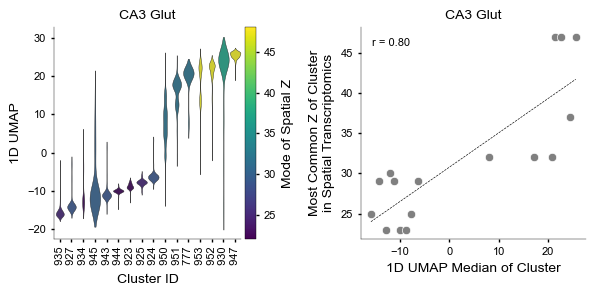

/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/1820521078.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(new_labels, rotation=90, ha='center', fontsize=8)


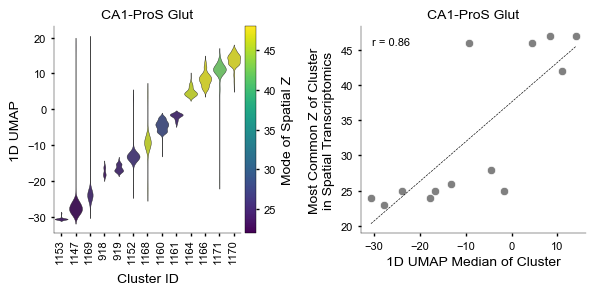

/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/1820521078.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(new_labels, rotation=90, ha='center', fontsize=8)


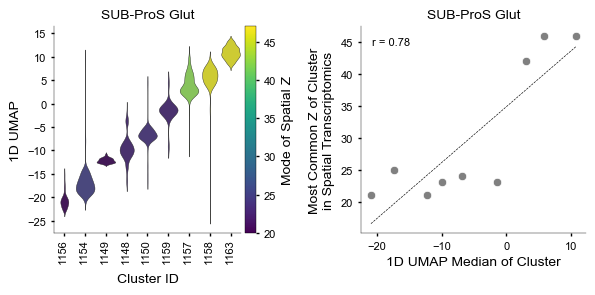

In [4]:
def plot_umap_1d_vs_spatial_z(rna_data_group, group, out_dir, z_col, save = True, palette = 'viridis'):
    # per-cell dataframe for violin
    plot_df = pd.DataFrame({
        'Cluster_v4': rna_data_group.obs['Cluster_v4'],
        'umap1d': rna_data_group.obsm['umap_1d'].squeeze(),
        'z_order': rna_data_group.obs[z_col]
    })

    # cluster ordering by median umap1d
    cluster_median = plot_df.groupby('Cluster_v4', observed=False)['umap1d'].median().sort_values()
    sorted_clusters = cluster_median.index.tolist()

    # cluster-level dataframe for scatter
    plot_df2 = plot_df.groupby('Cluster_v4', observed=False)[['umap1d', 'z_order']].median().loc[sorted_clusters].reset_index()

    # normalization for colorbar
    norm = plt.Normalize(plot_df['z_order'].min()-1, plot_df['z_order'].max()+1)
    cmap = plt.get_cmap(palette)

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(6.0, 3.0))

    # Violin plot (per-cell) colored by z_order
    sns.violinplot(
        data=plot_df,
        x='Cluster_v4',
        y='umap1d',
        order=sorted_clusters,
        inner=None,
        ax=ax0,
        palette=palette,
        hue='z_order',
        width=0.9,
        linewidth=0.3,
        hue_norm=norm
    )
    # colorbar for violin (use ScalarMappable)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax0, pad=0.02)
    cbar.set_label('Mode of Spatial Z', rotation=90)
    ax0.get_legend().remove() if ax0.get_legend() else None
    sns.despine(ax=ax0)

    # rotate and clean x labels
    new_labels = [label.get_text().replace("_", " ").replace("cluster", "") for label in ax0.get_xticklabels()]
    ax0.set_xticklabels(new_labels, rotation=90, ha='center', fontsize=8)
    ax0.set_xlabel('Cluster ID')
    ax0.set_ylabel('1D UMAP')
    ax0.set_title(f'{group}')

    # Scatter of cluster medians + regression + Spearman
    sns.scatterplot(data=plot_df2, x='umap1d', y='z_order', color='grey', ax=ax1)
    sns.regplot(data=plot_df2, x='umap1d', y='z_order', scatter=False, ax=ax1, color='black', line_kws={'linestyle':'--'}, ci=None)
    sns.despine(ax=ax1)
    ax1.set_ylabel('Most Common Z of Cluster\nin Spatial Transcriptomics')
    ax1.set_xlabel('1D UMAP Median of Cluster')
    spearman_corr, spearman_p = spearmanr(plot_df2['umap1d'], plot_df2['z_order'])
    ax1.text(0.05, 0.95, f'r = {spearman_corr:.2f}', transform=ax1.transAxes, verticalalignment='top')
    ax1.set_title(f'{group}')

    plt.tight_layout()
    if save:
        plt.savefig(out_dir / f'{group}_umap1d_and_spatial_z.svg', transparent=True, format='svg')
    plt.show()
    return sorted_clusters

for group in hpf_groups:
    rna_data_group = rna_data_groups[group]
    plot_umap_1d_vs_spatial_z(rna_data_group, group, RESULTS_DIR, z_col, save=True, palette='viridis')

## 2.1 Correlate gene expression (RNA) with the 1D UMAP coordinate

In [5]:
all_results_all_genes = {}
genes_keep = rna_data.var.index.tolist()

for g in hpf_groups:
    rna_data_group = rna_data_groups[g]
    umap_1d_values = rna_data_group.obsm['umap_1d'].squeeze()
    X = sparse.csc_matrix(rna_data_group[:, genes_keep].X)  # column access is fast in CSC
    correlations, p_values = [], []
    for j in range(len(genes_keep)):
        gene_expression = X[:, j].toarray().ravel()
        corr, p_val = spearmanr(gene_expression, umap_1d_values)
        correlations.append(corr)
        p_values.append(p_val)
    results_df = pd.DataFrame({
        'gene': genes_keep,
        'spearman_correlation': correlations,
        'p_value': p_values
    })
    results_df = results_df.reindex(results_df['spearman_correlation'].abs().sort_values(ascending=False).index)

    ## drop genes with undefined correlation (constant expression), then Benjamini-Hochberg correction
    results_df = results_df[results_df['spearman_correlation'].notna()].copy()
    results_df['adjusted_p_value'] = multipletests(results_df['p_value'], method='fdr_bh')[1]
    results_df.to_csv(RESULTS_DIR / f'RNA_gene_{g}.csv', index=False)
    all_results_all_genes[g] = results_df

/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/3367156317.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, p_val = spearmanr(gene_expression, umap_1d_values)
/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/3367156317.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, p_val = spearmanr(gene_expression, umap_1d_values)
/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/3367156317.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, p_val = spearmanr(gene_expression, umap_1d_values)


## 2.2 Visualize overlaps of gradient genes among subfields

In [6]:
## (re)load the saved gene correlation results
all_results_all_genes = {}
for g in hpf_groups:
    results_df = pd.read_csv(RESULTS_DIR / f'RNA_gene_{g}.csv', index_col=0)
    results_df['gene'] = results_df.index.values
    all_results_all_genes[g] = results_df

In [7]:
def plot_upset(result_list, group_col, groups, corr_thres=0, ylim=80, palette=None,
               ylabel='Number of Genes', save=False, out_dir=None, save_prefix=None):
    """UpSet plots of significant (FDR < 0.05, |rho| > corr_thres) features shared across groups,
    split by direction of the gradient."""
    sig_list = []
    for group in groups:
        res = result_list[group]
        sig = res[(res['adjusted_p_value'] < 0.05) & (res['spearman_correlation'].abs() > corr_thres)].copy()
        sig['group'] = group
        sig['var'] = sig.index if group_col == 'index' else sig[group_col]
        sig_list.append(sig)
    all_df = pd.concat(sig_list, axis=0)

    all_df_up = all_df[all_df['spearman_correlation'] > 0]
    all_df_down = all_df[all_df['spearman_correlation'] < 0]

    for df, direction, slug in zip([all_df_up, all_df_down],
                                   ['Anterior -> Posterior', 'Posterior -> Anterior'],
                                   ['anterior_to_posterior', 'posterior_to_anterior']):
        if df['group'].nunique() < 2:
            print(f'Not enough groups for {direction} genes, skipping upset plot...')
            continue
        print(f'Plotting {direction} genes...')
        memberships = [df.loc[df['var'] == var, 'group'].tolist() for var in df['var'].unique()]
        data = from_memberships(memberships)

        upset = UpSet(data, sort_by='cardinality', sort_categories_by=None,
                      subset_size='count', element_size=15, totals_plot_elements=0)
        if palette is not None:
            for group in df['group'].unique():
                upset.style_subsets(present=group, facecolor=palette[group])
            upset.style_subsets(min_degree=2, facecolor='grey')
        upset.plot()
        plt.ylabel(ylabel, fontsize=8)
        plt.ylim(0, ylim)
        plt.grid(False)
        plt.gcf().set_size_inches(3, 1.5)
        plt.suptitle(direction)
        plt.tight_layout()
        if save and out_dir is not None and save_prefix is not None:
            print(f'Saving upset plot for {direction} genes...')
            plt.savefig(out_dir / f'{save_prefix}_{slug}_corrthres_{corr_thres}.svg',
                        format='svg', bbox_inches='tight', transparent=True)
        plt.show()
    return all_df_up, all_df_down

Plotting Anterior -> Posterior genes...
Saving upset plot for Anterior -> Posterior genes...


/Users/daisydan/mambaforge3/envs/scvi-env/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/daisydan/mambaforge3/envs/scvi-env/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



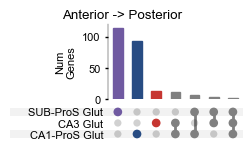

Plotting Posterior -> Anterior genes...
Saving upset plot for Posterior -> Anterior genes...


/Users/daisydan/mambaforge3/envs/scvi-env/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/daisydan/mambaforge3/envs/scvi-env/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



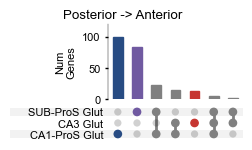

In [8]:
genes_up, genes_down = plot_upset(all_results_all_genes, 'gene', hpf_groups, corr_thres=0.5, ylim=120,
                                  save=True, out_dir=RESULTS_DIR, save_prefix='RNA_gene', ylabel='Num\nGenes',
                                  palette={g: GROUP_PALETTE[g] for g in hpf_groups})

## 2.3 Correlate accessibility of eRegulon peaks (ATAC) with the 1D UMAP coordinate

In [9]:
## eRegulon triplets (TF - region - gene) and the HPF ATAC cells x peaks matrix
## (already subset to eRegulon peaks by subset_atac_to_eregulon_peaks.py)
ereg_trip = pd.read_csv(EREGULON_TSV, sep='\t', index_col=0)
hpf_peaks = sc.read_h5ad(ATAC_PEAKS_H5AD)

In [10]:
n_bins = 30
group_bin_peak_sums_cpm = {}
group_bin_peak_sums = {}
group_bin_peak_totals = {}
hpf_peaks_sub = hpf_peaks[:, hpf_peaks.var_names.isin(ereg_trip.index.unique())]

for group in hpf_groups:
    print(f'Processing group: {group}')
    rna_group = rna_data_groups[group]
    # intersect cells between RNA group and hpf_peaks_sub
    common = rna_group.obs.index.intersection(hpf_peaks_sub.obs.index)
    if len(common) == 0:
        print(f'  No overlapping cells for group {group}, skipping.')
        continue
    common = list(common)  # ensure indexable

    # get umap1d for the intersected cells (preserve order)
    umap1d_series = pd.Series(rna_group.obsm['umap_1d'].squeeze(), index=rna_group.obs.index)
    umap1d_for_common = umap1d_series.loc[common]

    # bin the umap1d into quantile bins
    try:
        bins = pd.qcut(umap1d_for_common, q=n_bins, labels=False, duplicates='drop')
    except ValueError:
        # fallback to equal-width bins if qcut fails
        bins = pd.cut(umap1d_for_common, bins=n_bins, labels=False, duplicates='drop')
    bins = bins.astype(int)
    unique_bins = np.sort(bins.unique())

    # subset hpf_peaks_sub to the intersected cells in the same order
    hpf_peaks_group = hpf_peaks_sub[common, :]

    # get matrix
    X = hpf_peaks_group.X
    if sparse.issparse(X):
        X = X.tocsr()
    else:
        X = np.asarray(X)

    bin_sums_list = []
    for b in unique_bins:
        sel = np.where(bins.values == b)[0]
        if sel.size == 0:
            bin_sums = np.zeros(X.shape[1], dtype=float)
        else:
            sub = X[sel, :]
            bin_sums = np.asarray(sub.sum(axis=0)).ravel()
        bin_sums_list.append(bin_sums)

    # DataFrame: rows = bins, columns = peak names
    bin_idx = [int(b) for b in unique_bins]
    ca_bin_peak_sums = pd.DataFrame(bin_sums_list, index=bin_idx, columns=hpf_peaks_group.var_names)

    # total peak signal per bin (sum across peaks)
    ca_bin_peak_totals = ca_bin_peak_sums.sum(axis=1)
    ca_bin_peak_totals_nonzero = ca_bin_peak_totals.replace(0, np.nan)

    # CPM normalization per bin
    ca_bin_peak_sums_cpm = ca_bin_peak_sums.div(ca_bin_peak_totals_nonzero, axis=0).fillna(0) * 1e6

    group_bin_peak_sums[group] = ca_bin_peak_sums
    group_bin_peak_sums_cpm[group] = ca_bin_peak_sums_cpm
    group_bin_peak_totals[group] = ca_bin_peak_totals

    print(f'  bins: {len(bin_idx)}, peaks: {ca_bin_peak_sums.shape[1]}, cpm shape: {ca_bin_peak_sums_cpm.shape}')

# correlate peak CPM per bin with 1D-UMAP bin index (spearman) and adjust p-values per group

atac_bins_corr = {}
for group, cpm_df in group_bin_peak_sums_cpm.items():
    print(f'Computing spearman correlations for group: {group}')
    # ensure bins are sorted in order
    cpm_df = cpm_df.sort_index()
    bin_vals = cpm_df.index.astype(int).values  # numeric bin labels (0..n_bins-1)

    peaks = cpm_df.columns
    n_peaks = len(peaks)
    corrs = np.empty(n_peaks, dtype=float)
    pvals = np.empty(n_peaks, dtype=float)
    corrs.fill(np.nan)
    pvals.fill(np.nan)

    for j, peak in enumerate(peaks):
        col = cpm_df[peak].values
        try:
            r, p = spearmanr(bin_vals, col)
        except Exception:
            r, p = np.nan, np.nan
        corrs[j] = r
        pvals[j] = p

    res_df = pd.DataFrame({
        'spearman_correlation': corrs,
        'p_value': pvals
    }, index=peaks)

    # multiple testing correction (handle NaNs)
    mask = res_df['p_value'].notna()
    adj = np.full(res_df.shape[0], np.nan, dtype=float)
    if mask.sum() > 0:
        adj_vals = multipletests(res_df.loc[mask, 'p_value'].values, method='fdr_bh')[1]
        adj[mask.values] = adj_vals
    res_df['adjusted_p_value'] = adj

    # sort by absolute correlation
    res_df = res_df.reindex(res_df['spearman_correlation'].abs().sort_values(ascending=False).index)

    atac_bins_corr[group] = res_df

Processing group: CA3 Glut
  bins: 30, peaks: 49284, cpm shape: (30, 49284)
Processing group: CA1-ProS Glut
  bins: 30, peaks: 49284, cpm shape: (30, 49284)
Processing group: SUB-ProS Glut
  bins: 30, peaks: 49284, cpm shape: (30, 49284)
Computing spearman correlations for group: CA3 Glut
Computing spearman correlations for group: CA1-ProS Glut
Computing spearman correlations for group: SUB-ProS Glut


/var/folders/vj/yrjmzk3j6szdk3d76jbc864c0000gn/T/ipykernel_18625/1760289868.py:86: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = spearmanr(bin_vals, col)


In [11]:
## gradient genes / enhancers: |rho| > 0.5 and FDR < 0.05
thres = 0.5
gradient_genes_results = {}
gradient_enhancer_results = {}
for g in hpf_groups:
    res = all_results_all_genes[g]
    gradient_genes_results[g] = res[(res['adjusted_p_value'] < 0.05) & (res['spearman_correlation'].abs() > thres)]
    atac_res = atac_bins_corr[g]
    gradient_enhancer_results[g] = atac_res[(atac_res['adjusted_p_value'] < 0.05) & (atac_res['spearman_correlation'].abs() > thres)]

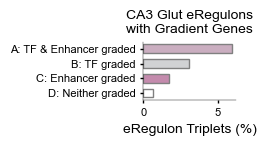

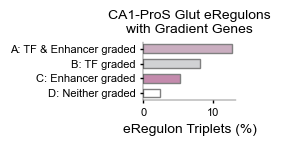

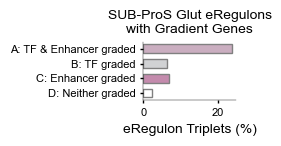

In [12]:
## percentage of eRegulon triplets (with gradient TFs and/or gradient enhancers) whose target gene is a gradient gene
eregulon_gradient_summary = {}
for i in hpf_groups:
    trip_df = ereg_trip
    n_triplets = trip_df.shape[0]
    gradient_tfs = gradient_genes_results[i]['gene'].tolist()
    gradient_enhancers = gradient_enhancer_results[i].index.tolist()
    triplets_with_gradient_tf = trip_df[trip_df['TF'].isin(gradient_tfs)]
    n_triplets_with_gradient_tf = triplets_with_gradient_tf[triplets_with_gradient_tf['Gene'].isin(gradient_tfs)]
    pct_triplets_with_gradient_tf_and_gene = n_triplets_with_gradient_tf.shape[0] / triplets_with_gradient_tf.shape[0] * 100
    pct_triplets_with_gradient_tf_and_gene_unique = n_triplets_with_gradient_tf['eRegulon_name'].nunique() / triplets_with_gradient_tf['eRegulon_name'].nunique() * 100

    triplets_with_gradient_enhancer = trip_df[trip_df.index.isin(gradient_enhancers)]
    n_triplets_with_gradient_enhancer = triplets_with_gradient_enhancer[triplets_with_gradient_enhancer['Gene'].isin(gradient_tfs)]
    pct_triplets_with_gradient_enhancer_and_gene = n_triplets_with_gradient_enhancer.shape[0] / triplets_with_gradient_enhancer.shape[0] * 100
    pct_triplets_with_gradient_enhancer_and_gene_unique = n_triplets_with_gradient_enhancer['eRegulon_name'].nunique() / triplets_with_gradient_enhancer['eRegulon_name'].nunique() * 100

    triplets_with_both = trip_df[(trip_df['TF'].isin(gradient_tfs)) & (trip_df.index.isin(gradient_enhancers))]
    n_triplets_with_both = triplets_with_both[triplets_with_both['Gene'].isin(gradient_tfs)]
    pct_triplets_with_both = n_triplets_with_both.shape[0] / triplets_with_both.shape[0] * 100
    pct_triplets_with_both_unique = n_triplets_with_both['eRegulon_name'].nunique() / triplets_with_both['eRegulon_name'].nunique() * 100

    non_gradient_tfs_or_enhancers = trip_df[~trip_df['TF'].isin(gradient_tfs) & ~trip_df.index.isin(gradient_enhancers)]
    n_non_gradient_tfs_or_enhancers = non_gradient_tfs_or_enhancers[non_gradient_tfs_or_enhancers['Gene'].isin(gradient_tfs)]
    pct_non_gradient_tf_and_enhancer = n_non_gradient_tfs_or_enhancers.shape[0] / non_gradient_tfs_or_enhancers.shape[0] * 100
    pct_non_gradient_tf_and_enhancer_unique = n_non_gradient_tfs_or_enhancers['eRegulon_name'].nunique() / non_gradient_tfs_or_enhancers['eRegulon_name'].nunique() * 100

    eregulon_gradient_summary[i] = {
        'n_triplets': n_triplets,
        'n_triplets_with_gradient_tf': n_triplets_with_gradient_tf.shape[0],
        'n_triplets_with_gradient_enhancer': n_triplets_with_gradient_enhancer.shape[0],
        'n_triplets_with_both': n_triplets_with_both.shape[0],
        'pct_with_gradient_tf': pct_triplets_with_gradient_tf_and_gene,
        'pct_with_gradient_enhancer': pct_triplets_with_gradient_enhancer_and_gene,
        'pct_with_both': pct_triplets_with_both,

        'pct_with_gradient_tf_unique': pct_triplets_with_gradient_tf_and_gene_unique,
        'pct_with_gradient_enhancer_unique': pct_triplets_with_gradient_enhancer_and_gene_unique,
        'pct_with_both_unique': pct_triplets_with_both_unique
    }


    ## bar plot
    barplot_df = pd.DataFrame({
        'A: TF & Enhancer graded': [pct_triplets_with_both],
        'B: TF graded': [pct_triplets_with_gradient_tf_and_gene],
        'C: Enhancer graded': [pct_triplets_with_gradient_enhancer_and_gene],
        'D: Neither graded': [pct_non_gradient_tf_and_enhancer]
    }, index=['Percentage'])
    fig2, ax2 = plt.subplots(figsize=(2.5, 1.5))
    sns.barplot(data=barplot_df, ax=ax2, edgecolor = 'grey',
        palette = ['#CFA9C1', '#D1D2D4', '#CE81AF', 'white'],
        orient='h',
        width=0.6
    )
    ax2.set_xlabel('eRegulon Triplets (%)')
    ax2.set_title(f'{i} eRegulons\nwith Gradient Genes')
    plt.tight_layout()
    sns.despine(ax=ax2)
    fig2.savefig(RESULTS_DIR / f'{i}_eregulon_triplet_gradient_percentage_barplot.svg', transparent=True, format='svg')
    plt.show()

## 3. Example triplet: TCF4 → chr3:128253794-128254295 → EPHA5 (Fig. 6I)

In [13]:
# Example eRegulon
group = 'CA3 Glut'

gene_oi = ['TCF4', 'EPHA5']
eregulon = 'TCF4_direct_+/+'
peak = 'chr3:128253794-128254295'

# check that the triplet exists in the eRegulon table
tcf4_ereg = ereg_trip[
    ereg_trip['Gene_signature_name'].str.startswith(eregulon)
]
display(
    tcf4_ereg[
        (tcf4_ereg['Gene'] == 'EPHA5') &
        (tcf4_ereg.index == peak)
    ]
)

# ---------------------------------------------------------
# RNA data for CA3 only
# ---------------------------------------------------------

rna_data_group = rna_data_groups[group]

umap1d = pd.Series(
    rna_data_group.obsm['umap_1d'].squeeze(),
    index=rna_data_group.obs_names,
    name='umap1d'
)

gene_expr = pd.DataFrame(
    rna_data_group[:, gene_oi].X.toarray(),
    index=rna_data_group.obs_names,
    columns=gene_oi
)

rna_plot_df = gene_expr.join(umap1d)

# ---------------------------------------------------------
# ATAC trajectory
# Use the EXACT binned CPM values used for atac_bins_corr
# ---------------------------------------------------------

if peak not in group_bin_peak_sums_cpm[group].columns:
    raise ValueError(f'{peak} is not present in the eRegulon peak matrix')

peak_cpm = (
    group_bin_peak_sums_cpm[group][peak]
    .sort_index()
    .copy()
)

,Gene,importance_R2G,rho_R2G,importance_x_rho,importance_x_abs_rho,TF,is_extended,eRegulon_name,Gene_signature_name,Region_signature_name,importance_TF2G,regulation,rho_TF2G,triplet_rank
Region,,,,,,,,,,,,,,
chr3:128253794-128254295,EPHA5,0.109399,0.347705,0.038039,0.038039,TCF4,False,TCF4_direct_+/+,TCF4_direct_+/+_(537g),TCF4_direct_+/+_(1298r),3.322607,1,0.398688,9667


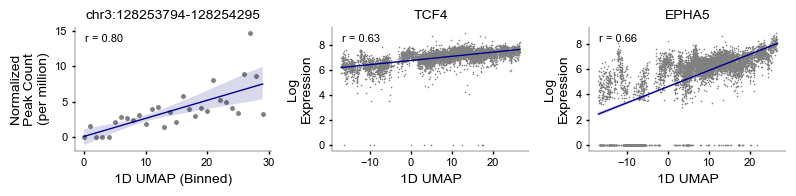

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(8, 2))

# ---------------------------------------------------------
# Peak accessibility
# ---------------------------------------------------------

sns.scatterplot(
    x=peak_cpm.index,
    y=peak_cpm.values,
    ax=ax[0],
    color='grey',
    s=15,
    rasterized=True
)

sns.regplot(
    x=peak_cpm.index,
    y=peak_cpm.values,
    ax=ax[0],
    scatter=False,
    color='darkblue',
    line_kws={'linewidth': 1}
)

peak_rho = spearmanr(
    peak_cpm.index,
    peak_cpm.values
).correlation

ax[0].text(
    0.05, 0.95,
    f'r = {peak_rho:.2f}',
    transform=ax[0].transAxes,
    fontsize=8,
    verticalalignment='top'
)

ax[0].set_xlabel('1D UMAP (Binned)')
ax[0].set_ylabel('Normalized\nPeak Count\n(per million)')
ax[0].set_title(peak)
sns.despine(ax=ax[0])

# ---------------------------------------------------------
# Gene expression
# ---------------------------------------------------------

for j, gene in enumerate(gene_oi, start=1):

    sns.scatterplot(
        data=rna_plot_df,
        x='umap1d',
        y=gene,
        ax=ax[j],
        s=1,
        edgecolor=None,
        color='grey',
        rasterized=True
    )

    sns.regplot(
        data=rna_plot_df,
        x='umap1d',
        y=gene,
        ax=ax[j],
        scatter=False,
        color='darkblue',
        line_kws={'linewidth': 1}
    )

    rho = spearmanr(
        rna_plot_df['umap1d'],
        rna_plot_df[gene]
    ).correlation

    ax[j].text(
        0.05, 0.95,
        f'r = {rho:.2f}',
        transform=ax[j].transAxes,
        fontsize=8,
        verticalalignment='top'
    )

    ax[j].set_xlabel('1D UMAP')
    ax[j].set_ylabel('Log\nExpression')
    ax[j].set_title(gene)
    sns.despine(ax=ax[j])

plt.tight_layout()

fig.savefig(
    RESULTS_DIR / 'CA3_Glut_TCF4_EPHA5_peak_gene_vs_umap1d_scatter.svg',
    bbox_inches='tight',
    transparent=True
)

plt.show()